# 04 — EDA: Bivariate and Multivariate Analysis
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 2 — Data Preparation (Exploratory Data Analysis)

**Project stage:** 4 of 16 — builds on Notebook 03's univariate findings

---

## 1. Objective

Notebook 03 looked at each behavioral variable in isolation. This notebook asks a different question: **how do these variables move together?**

Specifically we investigate the business relationships named in the project brief:
- `lead_time` vs. `adr`
- `total_stay_nights` vs. `adr`
- `lead_time` vs. cancellation
- `market_segment` vs. `adr`
- `customer_type` vs. `adr`
- Repeat guest status vs. booking behavior
- `total_of_special_requests` vs. booking value

...plus a full correlation heatmap across every numeric candidate feature, and a pairplot on a representative subset, to get an early multivariate view of the feature space before we ever touch a clustering algorithm.

**Why this matters for clustering specifically:** strongly correlated features carry overlapping (redundant) information. If we feed several strongly correlated features into a distance-based clustering algorithm unchanged, we are implicitly telling the algorithm that whatever those features have in common matters more than it should. Notebook 06 (Feature Engineering) will make concrete redundancy decisions — this notebook is where we gather the evidence for those decisions.

## 2. Business Context

Individually, "lead time is right-skewed" or "ADR has a long tail" tells the hotel very little it can act on. The business value shows up in *combinations*: does booking far in advance actually correlate with paying more or less? Do repeat guests behave differently from first-time guests beyond just the loyalty flag itself? Do guests who make more special requests also represent higher booking value?

These relationships are exactly the kind of structure a clustering algorithm is trying to find automatically — this notebook previews that structure manually and with statistics first, so that when we see the eventual clusters in Notebook 08 onward, we already have an informed sense of what "makes sense" versus what might be a modeling artifact.

**A reminder on cancellation:** `is_canceled` appears in several of these charts (as required by the business questions in the project brief) purely as a *descriptive, exploratory lens* — never as a clustering input. Any pattern involving cancellation is reported as an *observed association*, not a cause.

## 3. Imports

In [1]:
# pandas / numpy: data handling and statistics
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# os: portable file paths
import os


## 4. Configuration

In [2]:
RANDOM_STATE = 42

CLEANED_DATA_PATH = "../data/processed/02_cleaned_hotel_bookings.csv"

FIGURES_DIR = "../reports/figures"
CORRELATION_TABLE_PATH = "../reports/tables/04_correlation_matrix.csv"
GROUP_SUMMARY_DIR = "../reports/tables"

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(GROUP_SUMMARY_DIR, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

NUMERIC_CANDIDATES = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "booking_changes",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
]


## 5. Analysis / Implementation

### 5.1 Load Cleaned Data and Add Two Lightweight Helper Columns

For this exploratory notebook only, we compute `total_stay_nights` and `estimated_booking_value` early, since several of the business questions in the brief explicitly reference them. These are **exploratory helper columns here** — they will be formally created, documented, and justified as permanent engineered features in Notebook 06.

In [3]:
df = pd.read_csv(CLEANED_DATA_PATH)

# Total stay nights = weekend nights + week nights.
df["total_stay_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

# Estimated booking value = adr * total_stay_nights.
# This is an ESTIMATE based on the average daily rate and stay length; it is
# not a confirmed, realized revenue figure (taxes, discounts, or the effect
# of a cancellation are not reflected).
df["estimated_booking_value"] = df["adr"] * df["total_stay_nights"]

print("Shape:", df.shape)
df[["total_stay_nights", "estimated_booking_value"]].describe()


Shape: (87229, 34)


,total_stay_nights,estimated_booking_value
count,87229.000000,87229.000000
mean,3.628461,394.956436
std,2.742879,369.446365
min,0.000000,0.000000
25%,2.000000,153.000000
50%,3.000000,299.200000
75%,5.000000,504.000000
max,69.000000,7590.000000


### 5.2 Correlation Heatmap — Full Numeric Candidate Set

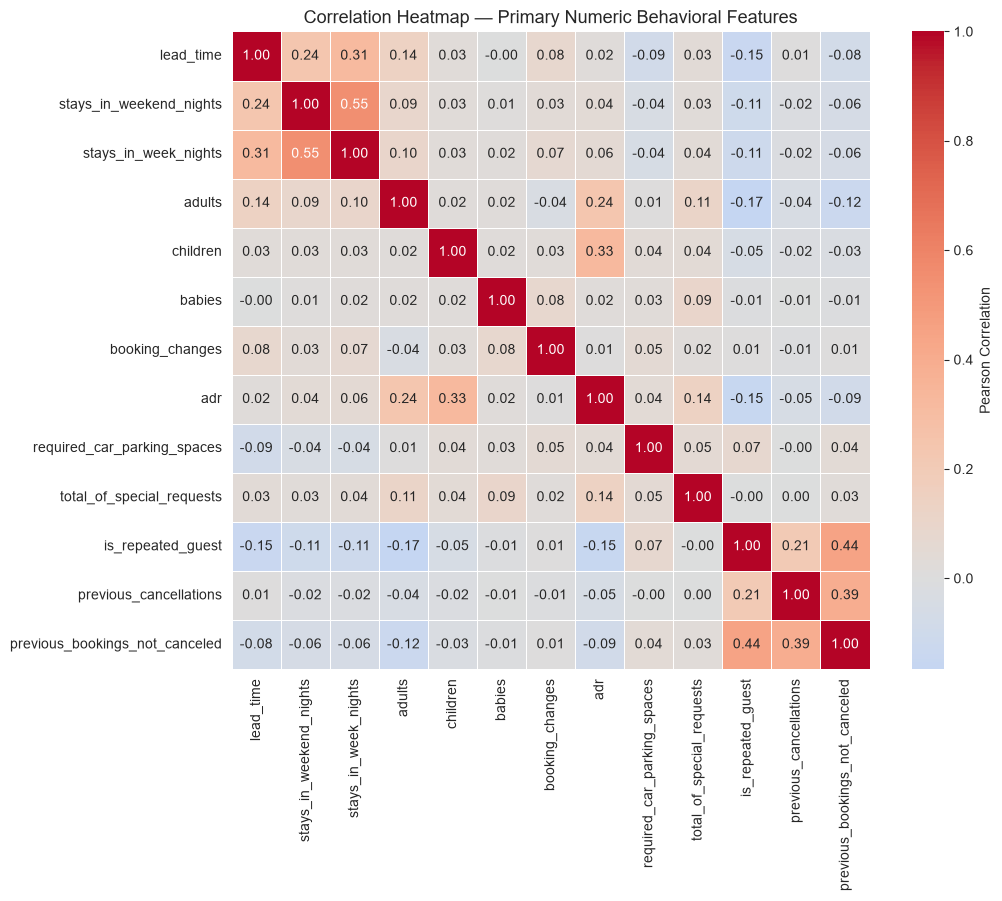

In [4]:
correlation_matrix = df[NUMERIC_CANDIDATES].corr()
correlation_matrix.to_csv(CORRELATION_TABLE_PATH)

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Pearson Correlation"},
)

ax.set_title("Correlation Heatmap — Primary Numeric Behavioral Features", fontsize=13)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_correlation_heatmap.png"))
plt.show()


**What this code does:** computes the Pearson correlation coefficient between every pair of the 13 primary numeric candidate features, and displays it as a heatmap.

**Why it's required:** clustering algorithms measure distance across all features simultaneously. Strongly correlated features effectively "double count" the same underlying signal, which can distort the resulting clusters. This heatmap is our evidence base for redundancy decisions in Notebook 06.

**What to expect:** most correlations in booking-behavior data of this kind are weak (near 0) — that's not a problem, it just means most of these features carry genuinely different information. A small number of moderate-to-strong pairs are worth a closer look.

**Findings (from the actual computed matrix above):**

- **`stays_in_weekend_nights` and `stays_in_week_nights`** show the strongest relationship among the stay-related features (r ≈ 0.55) — bookings with more week-night stays also tend to include more weekend nights, which makes intuitive sense (longer overall stays), but is worth remembering when we later engineer `total_stay_nights` as their sum.
- **`is_repeated_guest`, `previous_bookings_not_canceled`, and `previous_cancellations`** are moderately correlated with each other (r ≈ 0.39–0.44) — unsurprising, since all three describe the same underlying concept (prior relationship with the hotel) from different angles. This is a strong candidate for feature consolidation or careful selection in Notebook 06, to avoid over-weighting "loyalty" in the clustering distance calculation.
- **`adr` and `children`** show a moderate positive relationship (r ≈ 0.33) — bookings with children tend to have a somewhat higher average daily rate, plausibly reflecting larger room types or family-oriented rate plans.
- **`lead_time` and `stays_in_week_nights`** show a mild positive relationship (r ≈ 0.31) — bookings made further in advance tend to be for slightly longer stays.
- The great majority of pairs show weak correlation (well under 0.3), meaning most of these 13 features are contributing largely independent information — a good sign for clustering, since it means the feature set isn't dominated by a handful of redundant signals.

### 5.3 Lead Time vs. ADR

Correlation between lead_time and adr: 0.022


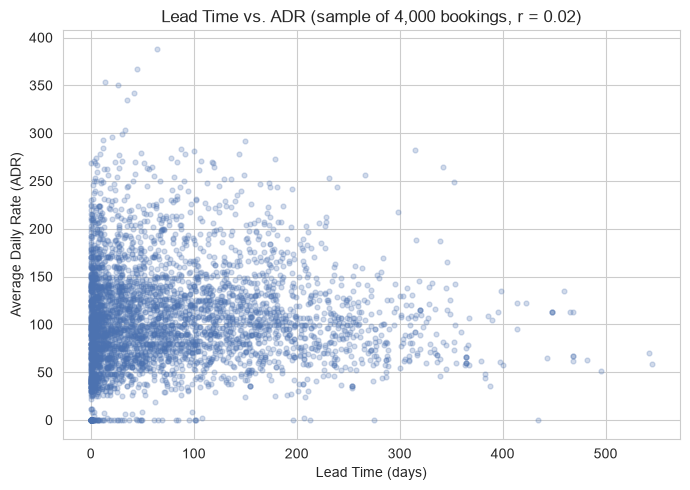

In [5]:
correlation_lead_adr = df["lead_time"].corr(df["adr"])
print("Correlation between lead_time and adr:", round(correlation_lead_adr, 3))

fig, ax = plt.subplots(figsize=(7, 5))

# Use a sample for the scatter plot - with 87,000+ points, plotting every
# single one makes the chart an unreadable solid block of color. A random
# sample preserves the overall shape of the relationship while staying readable.
sample = df.sample(n=4000, random_state=RANDOM_STATE)

ax.scatter(sample["lead_time"], sample["adr"], alpha=0.25, s=12, color="#4C72B0")

ax.set_title(f"Lead Time vs. ADR (sample of 4,000 bookings, r = {correlation_lead_adr:.2f})", fontsize=12)
ax.set_xlabel("Lead Time (days)")
ax.set_ylabel("Average Daily Rate (ADR)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_scatter_leadtime_adr.png"))
plt.show()


**Finding:** the correlation between `lead_time` and `adr` is essentially zero (r ≈ 0.02). Visually, the scatter plot shows no clear linear trend — bookings made far in advance are not, on average, meaningfully cheaper or more expensive than last-minute bookings in this data.

**Business interpretation:** this is a genuinely useful negative finding. It means "books early" and "pays a high or low rate" are **not the same behavioral signal** — a clustering result that separates early planners from last-minute bookers is not simply going to be a repackaged version of a price-based split. These are two independent axes of behavior worth capturing separately.

### 5.4 Total Stay Nights vs. ADR

Correlation between total_stay_nights and adr: 0.056


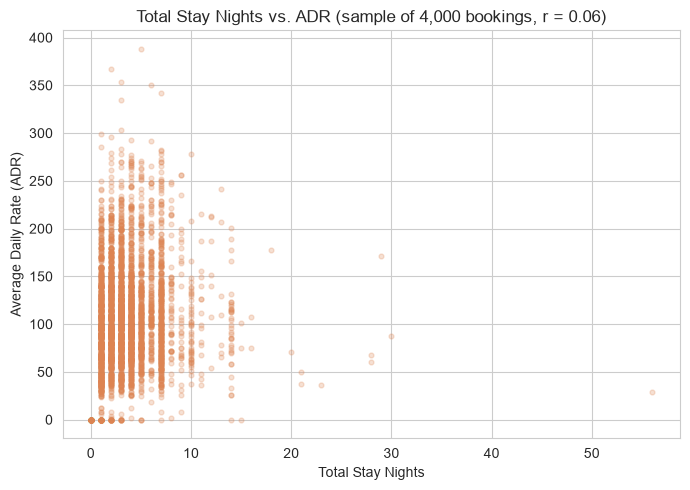

In [6]:
correlation_stay_adr = df["total_stay_nights"].corr(df["adr"])
print("Correlation between total_stay_nights and adr:", round(correlation_stay_adr, 3))

fig, ax = plt.subplots(figsize=(7, 5))

sample = df.sample(n=4000, random_state=RANDOM_STATE)

ax.scatter(sample["total_stay_nights"], sample["adr"], alpha=0.25, s=12, color="#DD8452")

ax.set_title(f"Total Stay Nights vs. ADR (sample of 4,000 bookings, r = {correlation_stay_adr:.2f})", fontsize=12)
ax.set_xlabel("Total Stay Nights")
ax.set_ylabel("Average Daily Rate (ADR)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_scatter_staynights_adr.png"))
plt.show()


**Finding:** like lead time, the relationship between stay length and ADR is very weak (r ≈ 0.06). Longer stays are not strongly associated with a higher or lower nightly rate in this data. **Business interpretation:** stay length and nightly rate appear to be largely independent behaviors — consistent with the idea that `estimated_booking_value` (rate × nights) captures genuinely combined information, not something already implied by either feature alone.

### 5.5 Lead Time vs. Cancellation (Exploratory Only)

In [7]:
cancellation_leadtime = df.groupby("is_canceled")["lead_time"].agg(["mean", "median", "std", "count"])
cancellation_leadtime.index = ["Not Canceled", "Canceled"]
cancellation_leadtime


,mean,median,std,count
Not Canceled,70.183581,38.0,81.652728,63220
Canceled,105.738306,80.0,91.846131,24009


C:\Users\Dell\AppData\Local\Temp\ipykernel_16316\1003275867.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Dell\AppData\Local\Temp\ipykernel_16316\1003275867.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Not Canceled", "Canceled"])


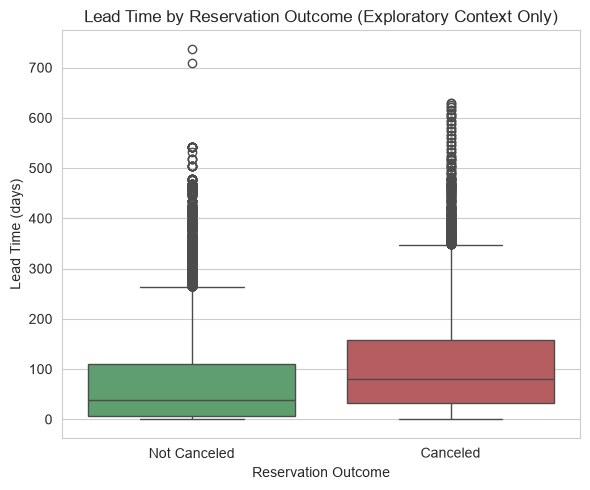

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.boxplot(
    data=df,
    x="is_canceled",
    y="lead_time",
    ax=ax,
    palette=["#55A868", "#C44E52"],
)

ax.set_title("Lead Time by Reservation Outcome (Exploratory Context Only)", fontsize=12)
ax.set_xlabel("Reservation Outcome")
ax.set_ylabel("Lead Time (days)")
ax.set_xticklabels(["Not Canceled", "Canceled"])

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_boxplot_leadtime_cancellation.png"))
plt.show()


**Finding:** canceled bookings have a noticeably higher average and median lead time (mean ≈ 106 days, median 80 days) than bookings that were not canceled (mean ≈ 70 days, median 38 days).

**Business interpretation:** bookings made far in advance show a **higher observed cancellation rate** than last-minute bookings. This makes intuitive business sense — the longer the gap between booking and arrival, the more opportunity there is for a guest's plans to change. We are careful with the wording here: this is an **observed association**, not a claim that booking early *causes* cancellation. This relationship is exactly why cancellation will be examined *per cluster* later (Notebook 14) rather than used to build the clusters themselves — early-planner behavior is a real, useful segment to identify regardless of its cancellation association, and folding cancellation into the clustering itself would risk defining "early planner" partly by its own outcome.

### 5.6 Market Segment vs. ADR

In [9]:
market_segment_adr = df.groupby("market_segment")["adr"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False)
market_segment_adr


,mean,median,count
market_segment,,,
Online TA,118.296093,110.71,51553
Direct,116.784056,107.00,11780
Aviation,100.613628,95.00,226
Offline TA/TO,81.948897,79.20,13855
Groups,75.184371,68.00,4921
Corporate,68.344298,65.00,4200
Undefined,15.000000,15.00,2
Complementary,3.093309,0.00,692


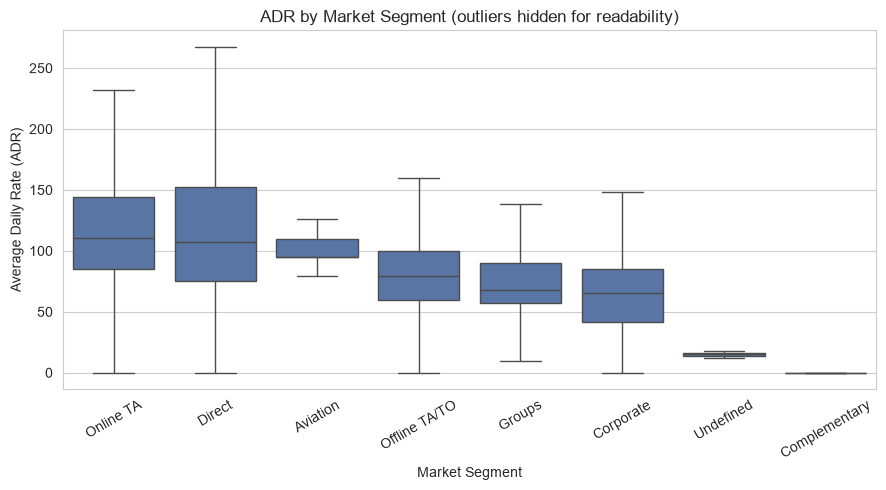

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

# Order the boxplot categories from highest to lowest average ADR, using the
# table computed above, so the chart is easy to read at a glance.
order = market_segment_adr.index

sns.boxplot(data=df, x="market_segment", y="adr", order=order, ax=ax, showfliers=False, color="#4C72B0")

ax.set_title("ADR by Market Segment (outliers hidden for readability)", fontsize=12)
ax.set_xlabel("Market Segment")
ax.set_ylabel("Average Daily Rate (ADR)")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_boxplot_marketsegment_adr.png"))
plt.show()


**Finding:** `Online TA` and `Direct` bookings command the highest average ADR (≈ €118 and €117 respectively), while `Corporate` (≈ €68) and `Groups` (≈ €75) bookings run noticeably cheaper on average — consistent with negotiated corporate/group rates. `Complementary` bookings average just €3, confirming these are essentially free/comp stays rather than a pricing anomaly.

**Business interpretation:** market segment is clearly linked to booking value, which makes it a strong **profiling variable** for describing clusters after they're found (Notebook 13/14), even though — as a high-level categorical describing acquisition channel rather than moment-to-moment behavior — its role as a direct clustering *input* will be weighed carefully against the numeric behavioral features in Notebook 06.

### 5.7 Customer Type vs. ADR

In [11]:
customer_type_adr = df.groupby("customer_type")["adr"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False)
customer_type_adr


,mean,median,count
customer_type,,,
Transient,110.302799,102.30,71862
Contract,92.871381,90.95,3135
Transient-Party,87.927138,81.62,11691
Group,84.817930,75.00,541


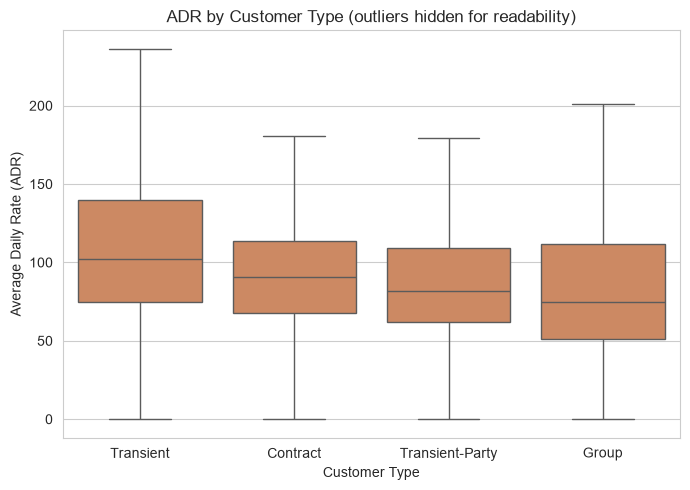

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

order = customer_type_adr.index

sns.boxplot(data=df, x="customer_type", y="adr", order=order, ax=ax, showfliers=False, color="#DD8452")

ax.set_title("ADR by Customer Type (outliers hidden for readability)", fontsize=12)
ax.set_xlabel("Customer Type")
ax.set_ylabel("Average Daily Rate (ADR)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_boxplot_customertype_adr.png"))
plt.show()


**Finding:** `Transient` bookings (individual, non-contract, non-group) show the highest average ADR (≈ €110), while `Group` bookings are the lowest (≈ €85) — consistent with the market-segment pattern above, since group and contract bookings typically involve negotiated rates.

### 5.8 Repeat Guest Status vs. Booking Behavior

In [13]:
repeat_guest_behavior = df.groupby("is_repeated_guest")[
    ["lead_time", "adr", "booking_changes", "previous_cancellations", "total_of_special_requests"]
].mean()
repeat_guest_behavior.index = ["First-Time / Not Flagged", "Repeated Guest"]

repeat_guest_behavior


,lead_time,adr,booking_changes,previous_cancellations,total_of_special_requests
First-Time / Not Flagged,82.483581,108.160809,0.267474,0.015072,0.699127
Repeated Guest,17.278918,65.584234,0.293488,0.412727,0.694321


In [14]:
cancellation_rate_by_repeat = df.groupby("is_repeated_guest")["is_canceled"].mean()
cancellation_rate_by_repeat.index = ["First-Time / Not Flagged", "Repeated Guest"]

print("Observed cancellation rate by repeat-guest status:")
print((cancellation_rate_by_repeat * 100).round(1).astype(str) + "%")


Observed cancellation rate by repeat-guest status:
First-Time / Not Flagged    28.3%
Repeated Guest               7.7%
Name: is_canceled, dtype: str


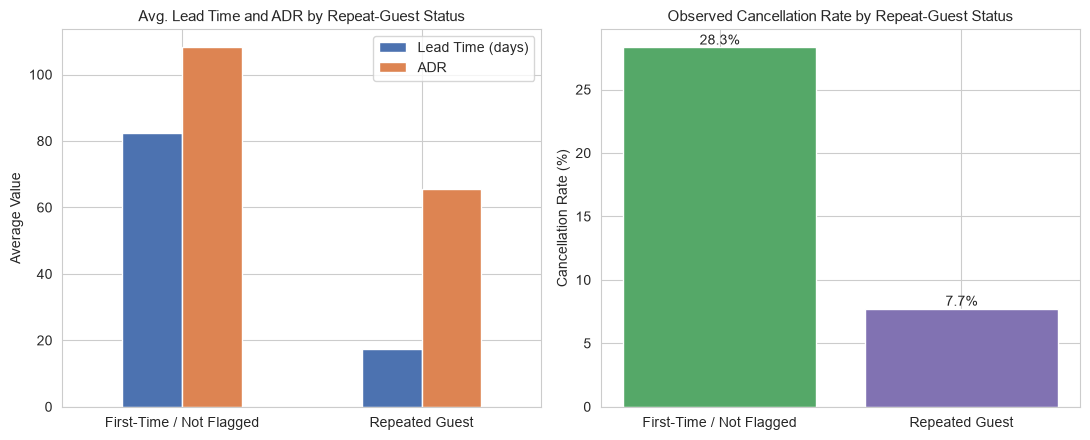

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Panel 1: lead time and ADR comparison
metrics_1 = repeat_guest_behavior[["lead_time", "adr"]]
metrics_1.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Avg. Lead Time and ADR by Repeat-Guest Status", fontsize=11)
axes[0].set_xlabel("")
axes[0].set_ylabel("Average Value")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(["Lead Time (days)", "ADR"])

# Panel 2: observed cancellation rate comparison
axes[1].bar(cancellation_rate_by_repeat.index, (cancellation_rate_by_repeat * 100), color=["#55A868", "#8172B2"])
axes[1].set_title("Observed Cancellation Rate by Repeat-Guest Status", fontsize=11)
axes[1].set_ylabel("Cancellation Rate (%)")
for i, value in enumerate(cancellation_rate_by_repeat * 100):
    axes[1].text(i, value, f"{value:.1f}%", ha="center", va="bottom")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_repeatguest_behavior_comparison.png"))
plt.show()


**Finding:** bookings flagged as repeated guests show a markedly shorter average lead time (≈ 17 days vs. ≈ 82 days), a lower average ADR (≈ €66 vs. €108), and a much lower observed cancellation rate (≈ 7.7% vs. 28.3%) than non-repeat bookings. Special-request behavior is nearly identical between the two groups (≈ 0.69–0.70 on average either way).

**Business interpretation:** the loyalty signal in this data corresponds to a distinctive behavioral profile — repeat guests book close to arrival (likely because they already know and trust the property), typically at a lower rate (possibly loyalty pricing or simply booking during off-peak periods), and follow through on their bookings far more reliably. This is a strong, multi-dimensional signal, not just a single flag — a promising sign that a "loyal guest" segment may emerge as genuinely distinct in the clustering stage. As always, cancellation rate here is reported as an **observed association**, not attributed causally to repeat-guest status.

### 5.9 Total Special Requests vs. Booking Value

In [16]:
special_requests_value = df.groupby("total_of_special_requests")[["adr", "estimated_booking_value"]].mean()
special_requests_value


,adr,estimated_booking_value
total_of_special_requests,,
0,99.889303,363.283787
1,109.785310,407.225745
2,118.699924,454.302729
3,125.232939,508.136037
4,131.088687,586.382938
5,129.980000,623.368056


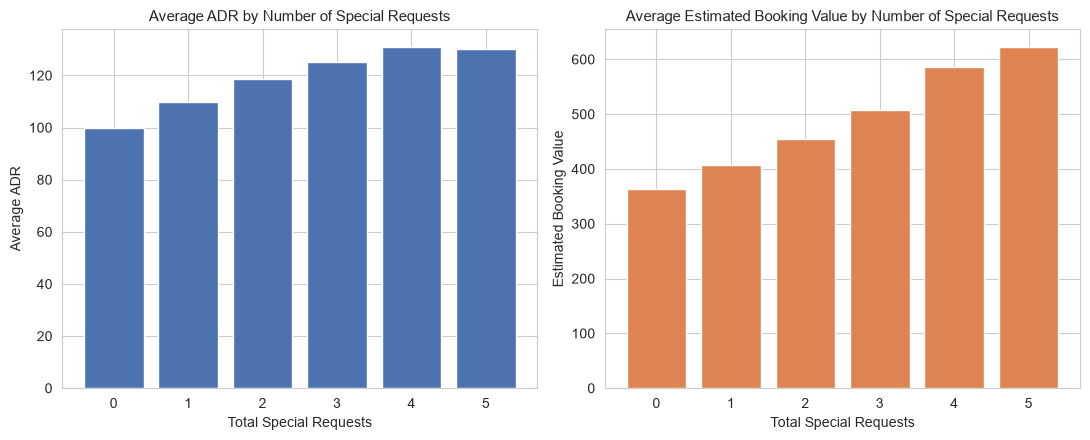

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].bar(special_requests_value.index.astype(str), special_requests_value["adr"], color="#4C72B0")
axes[0].set_title("Average ADR by Number of Special Requests", fontsize=11)
axes[0].set_xlabel("Total Special Requests")
axes[0].set_ylabel("Average ADR")

axes[1].bar(special_requests_value.index.astype(str), special_requests_value["estimated_booking_value"], color="#DD8452")
axes[1].set_title("Average Estimated Booking Value by Number of Special Requests", fontsize=11)
axes[1].set_xlabel("Total Special Requests")
axes[1].set_ylabel("Estimated Booking Value")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_specialrequests_value.png"))
plt.show()


**Finding:** both average ADR and average estimated booking value increase steadily and fairly consistently as the number of special requests goes up — from an ADR of ≈ €100 at zero requests to ≈ €130 at four requests, and estimated booking value roughly following the same climbing pattern.

**Business interpretation:** guests who engage more with the hotel by making special requests tend to represent higher booking value. This is a genuinely useful, actionable pattern — it suggests `total_of_special_requests` isn't just a service-load indicator for staffing, but also a plausible **value signal** worth its place among the primary clustering candidates.

### 5.10 A Business Curiosity: Deposit Type vs. Cancellation

In [18]:
deposit_cancellation = df.groupby("deposit_type")["is_canceled"].agg(["mean", "count"])
deposit_cancellation.columns = ["cancellation_rate", "n_bookings"]
deposit_cancellation["cancellation_rate_pct"] = (deposit_cancellation["cancellation_rate"] * 100).round(1)
deposit_cancellation.sort_values("cancellation_rate", ascending=False)


,cancellation_rate,n_bookings,cancellation_rate_pct
deposit_type,,,
Non Refund,0.947013,1038,94.7
No Deposit,0.267181,86084,26.7
Refundable,0.242991,107,24.3


**Finding:** bookings with a `Non Refund` deposit type show an unusually high observed cancellation rate (≈ 94.7%) compared to `No Deposit` (≈ 26.7%) and `Refundable` (≈ 24.3%) bookings — despite `Non Refund` representing a small share of total bookings. This is a striking, counter-intuitive pattern: one might expect a non-refundable deposit to *discourage* cancellation, not coincide with it almost always happening.

**Business interpretation:** we deliberately do **not** speculate about the mechanism here (it could reflect a specific booking channel's practices, a data-recording convention, or something else entirely) — the point of this notebook is to surface the pattern with evidence, not explain it. This is flagged clearly for a closer, dedicated look during post-clustering cancellation analysis (Notebook 14), where we can check whether this pattern is concentrated in a particular cluster or market segment.

### 5.11 Pairplot — Representative Behavioral Subset

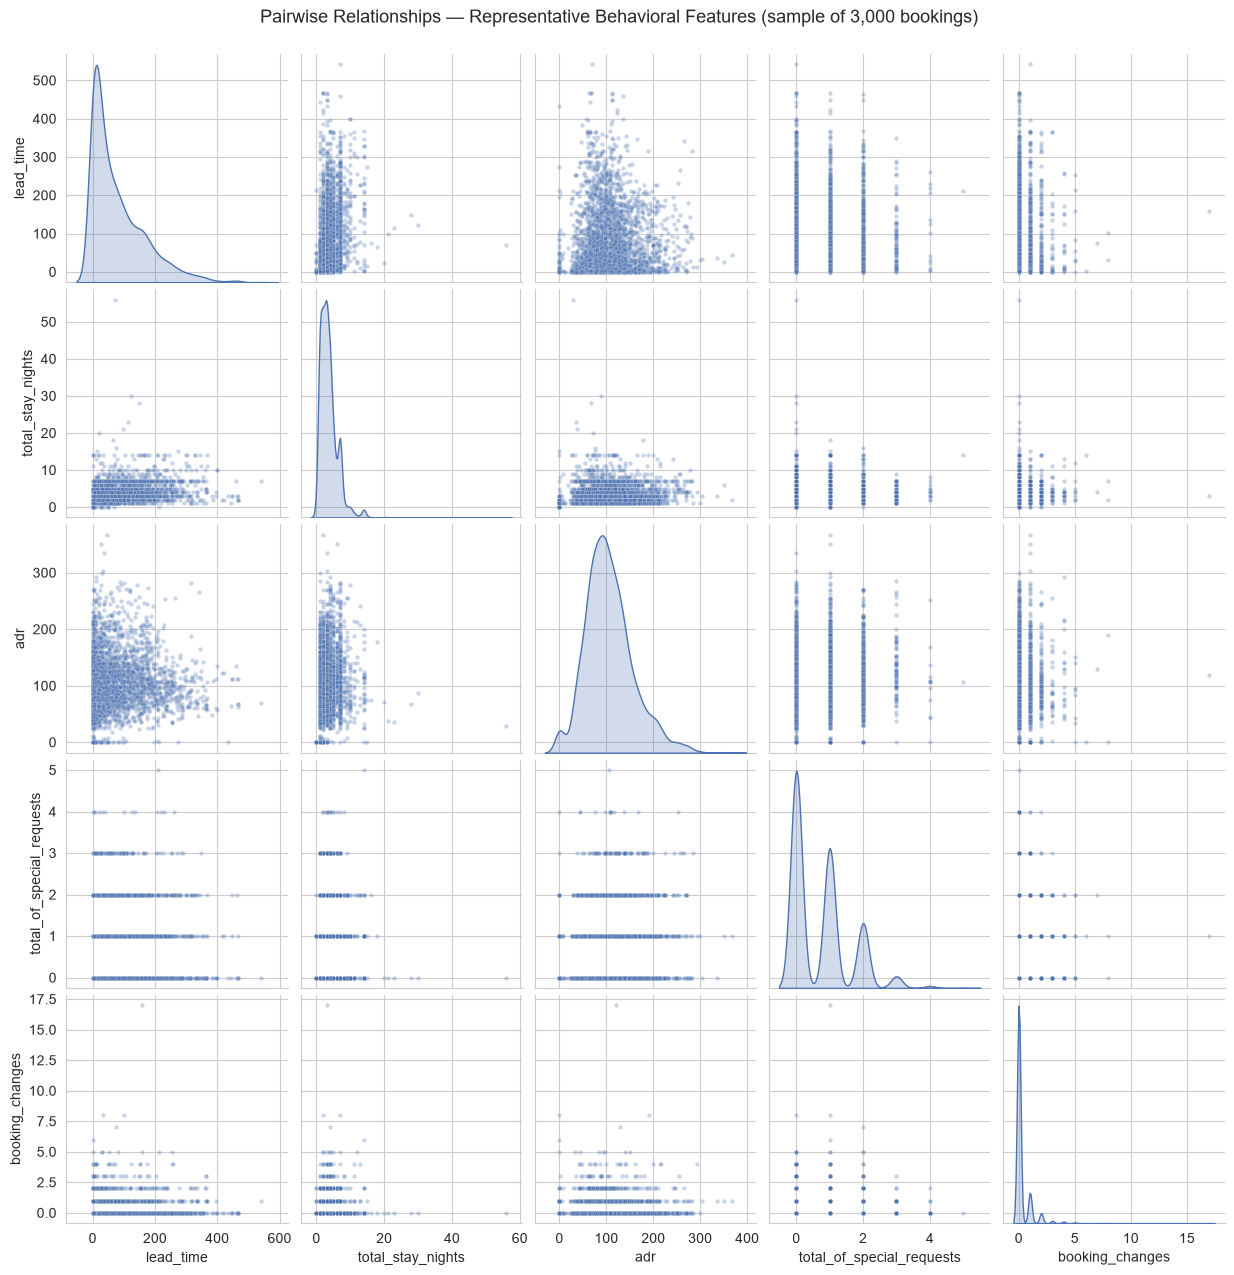

In [19]:
# A full pairplot across all 13 numeric candidates would be both visually
# overwhelming and slow to render. We select five representative features
# that capture distinct behavioral dimensions (timing, stay length, value,
# and engagement), and use a random sample of rows for rendering speed -
# this is a visualization choice, not a change to the underlying data.
pairplot_features = ["lead_time", "total_stay_nights", "adr", "total_of_special_requests", "booking_changes"]

pairplot_sample = df[pairplot_features].sample(n=3000, random_state=RANDOM_STATE)

pairplot_grid = sns.pairplot(
    pairplot_sample,
    diag_kind="kde",
    plot_kws={"alpha": 0.3, "s": 10, "color": "#4C72B0"},
    diag_kws={"color": "#4C72B0"},
)

pairplot_grid.fig.suptitle(
    "Pairwise Relationships — Representative Behavioral Features (sample of 3,000 bookings)",
    y=1.02, fontsize=13,
)

pairplot_grid.savefig(os.path.join(FIGURES_DIR, "04_pairplot_behavioral_subset.png"))
plt.show()


**Finding:** the pairplot confirms, visually, what the correlation heatmap already told us numerically — no strong linear relationships jump out between these five features. Each scatter panel shows a diffuse cloud rather than a clear line or curve, and the diagonal KDE plots reconfirm the right-skewed, zero-inflated shapes seen in Notebook 03.

**Business interpretation:** this is a genuinely encouraging sign for the clustering stage. If these behavioral dimensions were all just proxies for one another, clustering wouldn't be able to find much more structure than a single dominant axis. The lack of strong pairwise structure suggests there is real, multi-dimensional behavioral variation for a clustering algorithm to work with — though of course we won't know how well-separated that structure is until we actually run the models (Notebook 08 onward).

## 7. Findings

- `lead_time` and `total_stay_nights` are essentially uncorrelated with `adr` (r ≈ 0.02 and 0.06) — booking timing and stay length behavior appear to be independent of pricing behavior, meaning they capture genuinely distinct information rather than restating price in a different form.
- Longer lead times are associated with a higher observed cancellation rate (mean 106 vs. 70 days) — a real pattern worth tracking, but reported as an association only, and deliberately kept out of the clustering inputs to avoid defining behavior by its own outcome.
- `market_segment` and `customer_type` both show a clear, real relationship with ADR — Online TA/Direct and Transient bookings pay the most; Corporate/Group bookings pay noticeably less — useful primarily as **profiling** context.
- Repeat-guest status corresponds to a genuinely distinct multi-dimensional behavioral profile: shorter lead time, lower ADR, and a much lower observed cancellation rate — a strong candidate signal for a future loyalty-oriented cluster.
- `total_of_special_requests` climbs consistently with both ADR and estimated booking value, supporting its inclusion as a value-adjacent behavioral feature, not just a service-load indicator.
- A striking, unexplained pattern was found between `deposit_type = Non Refund` and an extremely high observed cancellation rate (≈ 94.7%) — flagged for deeper investigation after clustering, not explained here.
- The correlation heatmap and pairplot together show that most of the 13 primary numeric candidates carry largely independent information, with the clearest redundancy concentrated in the three "prior relationship" features (`is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled`) and, to a lesser extent, the two stay-length features.

## 8. Business Interpretation

This notebook's biggest takeaway is that booking behavior in this data genuinely has **multiple, largely independent dimensions** — timing, stay length, value, engagement, and loyalty don't collapse into one or two dominant signals. That's a good sign for a segmentation project: it means there's real structure for clustering to find, rather than one obvious axis dressed up as many variables.

It also gives the hotel two early, concrete, evidence-backed observations worth acting on regardless of the eventual clustering result: repeat guests behave in a consistently lower-risk, lower-lead-time way that could inform loyalty-program targeting, and guests who make more special requests tend to represent higher booking value, which could inform how service-heavy requests are staffed and prioritized.

## 9. Conclusion

We examined the relationships the project brief called for — lead time vs. ADR, stay length vs. ADR, lead time vs. cancellation, market segment and customer type vs. ADR, repeat-guest behavior, and special requests vs. value — backed by a full correlation heatmap and a representative pairplot. The main structural finding is that the primary numeric candidates are mostly independent of one another, with the clearest redundancy in the three loyalty-related features, which will be addressed directly in feature selection.

**Next notebook (05 — Outlier Analysis):** now that we understand both individual distributions and cross-variable relationships, we move to a dedicated, rigorous outlier investigation — using IQR bounds, percentile analysis, and business reasoning — before making any final decision about which extreme values to retain, cap, transform, or exclude.